# SAMS Fusion: Risk Classification

SAMS (Smart Accident Monitoring System) watches a worker near a machine. Each live frame produces measurements from several models and sensors. The fusion model turns them into one risk level, **NORMAL, CAUTION or DANGER**, which drives the buzzer, the status LEDs and the alerts. This notebook trains that model.

The live service (`monitoring/services/control_center.py` and `fusion_inference.py`) loads `models/fusion/best_fusion_model/model.joblib`. From its `metadata.json` it reads the class names, the input columns, the zone limits, the motion window the tracker must use, and the values that stand for "nobody in the frame". A retrained model with different inputs therefore needs no code change.

## Inputs (fusion contract)

| Input | Source | Meaning |
|---|---|---|
| `worker_detected` | PPE model's person class | 1 when a worker is in the frame |
| `worker_distance` | Distance network, or the ToF sensor when close | Metres from the machine |
| `inside_caution_zone`, `inside_danger_zone` | Distance and `zones_m` | 1 inside the zone |
| `worker_speed`, `approaching_machine` | Tracker over recent distances | Speed (m/s); 1 when the distance is shrinking |
| `vision_confidence` | Person detector | Confidence of the selected worker |
| `ppe_missing` | PPE model | 1 when a required item is detected as missing |
| `machine_active` | Machine-state model on the accelerometer | 1 when the machine runs |
| `vibration_state`, `vibration_anomaly_score` | Vibration model on the accelerometer | 1 when abnormal; P(ABNORMAL) |
| `fire_score`, `smoke_score` | Hazard detector | Strongest box above its per-class threshold, 0 when none |
| `fall_detected` | Accident detector | 1 when a worker is lying down |

Version 1 used the first ten inputs only. Fire, smoke, falls and PPE were measured live but could not change the risk level.

**Nobody in the frame.** The person inputs then take fixed values (`ABSENT_WORKER` below): far away, outside both zones, not moving, confidence 0, no PPE problem. The values are saved in the model's metadata, and the live service fills the same ones. An empty frame therefore gets a decision (normally NORMAL) instead of "not measured".

## Risk rules

The labels encode a safety policy. Each rule names its reason, and the first rule that applies sets the label:

| Level | Rule | Reasoning |
|---|---|---|
| DANGER | Fire detected | Fire endangers everyone, wherever the worker is |
| DANGER | A fallen worker | A possible injury needs an immediate response |
| DANGER | Machine running and worker inside the danger zone | Contact with moving parts is possible |
| DANGER | Machine running, worker in the caution zone and approaching fast | Will be in the danger zone within about a second |
| CAUTION | Smoke detected | A possible fire that is not yet confirmed |
| CAUTION | Machine running and worker in the caution zone | Close to a running machine |
| CAUTION | Machine stopped and worker in the danger zone | Maintenance-type closeness; the machine could start |
| CAUTION | Machine running with abnormal vibration and worker nearby | A faulty machine near a person |
| CAUTION | PPE missing and worker near a running machine | Unprotected worker close to a hazard |
| NORMAL | Otherwise | No hazard close to anyone |

Abnormal vibration matters only while the machine runs. The fire and smoke thresholds are the per-class thresholds of the hazard model (from `models/vision/hazard/metadata.json` when it is on Drive).

## Data

When `datasets/fusion/fusion_experiment_logs.csv` exists on Drive, the notebook trains on those **real rows**: labelled trials recorded live, and reviewed Archive moments (MLOps → Download training set, unzipped at the SAMS folder). Otherwise it generates **synthetic trials** from scenarios that imitate how the live measurements behave (one frame every 0.4 s, as the live page polls), labelled by the rules above. Synthetic data proves the pipeline and the input contract. Only real rows can show how often the measurements are wrong on site.

## Experiments and selection

Random Forest, XGBoost, an RBF SVM and an MLP are trained on the same trial-level split. A trial is never split between training and test. The winner has the highest **validation DANGER recall**, because a missed danger is the costliest error; ties go to the higher validation macro-F1. Test metrics are reported but never used to choose. The promoted model must also give the expected label on a set of hand-written **check scenarios** (Section 6.3); the best-ranked experiment that passes them all is promoted.

## Sections

| § | Content |
|---|---|
| 0 | Setup, configuration, input contract, rules |
| 1 | Dataset: real logs or synthetic scenarios |
| 2 | Exploratory data analysis |
| 3 | Trial holdout split |
| 4 | Experiment utilities |
| 5 | Experiments |
| 6 | Comparison, check scenarios, promotion |
| 7 | Limitations |

## 0. Setup

### 0.1 Paths

In Colab, models and results live on Google Drive (`MyDrive/SAMS`) and the generated dataset on the VM's local disk. Locally, the repository root plays the role of Drive.

In [1]:
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    SAMS_ROOT = Path("/content/SAMS")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")
    here = Path.cwd().resolve()
    DRIVE_ROOT = next((p for p in (here, here.parent) if (p / "manage.py").exists()), Path("./SAMS_drive_mirror"))

MODELS_DIR = DRIVE_ROOT / "models" / "fusion"
RESULTS_DIR = DRIVE_ROOT / "results" / "fusion"
DATA_DIR = SAMS_ROOT / "datasets" / "fusion"
REAL_LOG = DRIVE_ROOT / "datasets" / "fusion" / "fusion_experiment_logs.csv"
HAZARD_METADATA = DRIVE_ROOT / "models" / "vision" / "hazard" / "metadata.json"
for folder in (MODELS_DIR, RESULTS_DIR, DATA_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("MODELS_DIR: ", MODELS_DIR)
print("RESULTS_DIR:", RESULTS_DIR)

Mounted at /content/drive
MODELS_DIR:  /content/drive/MyDrive/SAMS/models/fusion
RESULTS_DIR: /content/drive/MyDrive/SAMS/results/fusion


### 0.2 Packages

In [2]:
import subprocess
import sys

PACKAGES = ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn==1.6.1", "joblib", "xgboost==3.4.1"]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])

In [3]:
import json
import random
import shutil
import warnings
from datetime import datetime, timezone
from typing import Any, Dict, List, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

### 0.3 Configuration

Every setting that changes the result is set here with its meaning. The zones and the absent-worker values are saved into the model's metadata, and the live service reads them from there.

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

CLASS_NAMES = ["NORMAL", "CAUTION", "DANGER"]
LABEL_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}

CAUTION_ZONE_M = 2.0
DANGER_ZONE_M = 0.8
NEARBY_M = 1.5 * CAUTION_ZONE_M
FAST_APPROACH_MPS = 0.8

hazard_class_conf = json.loads(HAZARD_METADATA.read_text()).get("class_conf", {}) if HAZARD_METADATA.exists() else {}
FIRE_ALARM_SCORE = float(hazard_class_conf.get("fire", 0.05))
SMOKE_ALARM_SCORE = float(hazard_class_conf.get("smoke", 0.374))
VIBRATION_ABNORMAL_SCORE = 0.5

ABSENT_WORKER = {
    "worker_distance": 10.0,
    "inside_caution_zone": 0.0,
    "inside_danger_zone": 0.0,
    "worker_speed": 0.0,
    "approaching_machine": 0.0,
    "vision_confidence": 0.0,
    "ppe_missing": 0.0,
}

N_TRIALS_PER_SCENARIO = 12
SAMPLES_PER_TRIAL = 50
FRAME_DT_S = 0.4
MOTION_WINDOW_S = 1.5
MLP_MAX_ITER = 300
MLP_PATIENCE = 15

config_table = pd.DataFrame([
    {"setting": "SEED", "value": SEED, "meaning": "Seed for scenario generation, splits and models"},
    {"setting": "CAUTION_ZONE_M", "value": CAUTION_ZONE_M, "meaning": "Caution zone radius around the machine (m)"},
    {"setting": "DANGER_ZONE_M", "value": DANGER_ZONE_M, "meaning": "Danger zone radius around the machine (m)"},
    {"setting": "NEARBY_M", "value": NEARBY_M, "meaning": "Range where a faulty machine or missing PPE matters (m)"},
    {"setting": "FAST_APPROACH_MPS", "value": FAST_APPROACH_MPS, "meaning": "Approach speed that turns the caution zone into DANGER (m/s)"},
    {"setting": "FIRE_ALARM_SCORE", "value": FIRE_ALARM_SCORE, "meaning": "Fire score that counts as fire (hazard model's fire threshold)"},
    {"setting": "SMOKE_ALARM_SCORE", "value": SMOKE_ALARM_SCORE, "meaning": "Smoke score that counts as smoke (hazard model's smoke threshold)"},
    {"setting": "VIBRATION_ABNORMAL_SCORE", "value": VIBRATION_ABNORMAL_SCORE, "meaning": "P(ABNORMAL) above which the vibration model says ABNORMAL"},
    {"setting": "N_TRIALS_PER_SCENARIO", "value": N_TRIALS_PER_SCENARIO, "meaning": "Synthetic trials per scenario"},
    {"setting": "SAMPLES_PER_TRIAL", "value": SAMPLES_PER_TRIAL, "meaning": "Frames per synthetic trial"},
    {"setting": "FRAME_DT_S", "value": FRAME_DT_S, "meaning": "Seconds between frames (the live page polls every 0.4 s)"},
    {"setting": "MOTION_WINDOW_S", "value": MOTION_WINDOW_S, "meaning": "Seconds of distance history the live tracker fits speed to"},
    {"setting": "MLP_MAX_ITER", "value": MLP_MAX_ITER, "meaning": "MLP epoch limit"},
    {"setting": "MLP_PATIENCE", "value": MLP_PATIENCE, "meaning": "MLP early-stopping patience"},
]).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)
print("Hazard thresholds from", HAZARD_METADATA if hazard_class_conf else "defaults (hazard metadata not on Drive)")

,value,meaning
setting,,
SEED,42.000,"Seed for scenario generation, splits and models"
CAUTION_ZONE_M,2.000,Caution zone radius around the machine (m)
DANGER_ZONE_M,0.800,Danger zone radius around the machine (m)
NEARBY_M,3.000,Range where a faulty machine or missing PPE ma...
FAST_APPROACH_MPS,0.800,Approach speed that turns the caution zone int...
FIRE_ALARM_SCORE,0.050,Fire score that counts as fire (hazard model's...
SMOKE_ALARM_SCORE,0.374,Smoke score that counts as smoke (hazard model...
VIBRATION_ABNORMAL_SCORE,0.500,P(ABNORMAL) above which the vibration model sa...
N_TRIALS_PER_SCENARIO,12.000,Synthetic trials per scenario


Hazard thresholds from /content/drive/MyDrive/SAMS/models/vision/hazard/metadata.json


### 0.4 Input contract and risk rules

`FEATURE_COLS` is the order the live service builds a row in. `assign_risk` is the safety policy from the overview, written once and used for every synthetic label and for the check scenarios in Section 6.3. It returns the label and the name of the rule that set it, so every error can be traced to a rule.

In [5]:
FEATURE_COLS = [
    "worker_detected",
    "worker_distance",
    "inside_caution_zone",
    "inside_danger_zone",
    "worker_speed",
    "approaching_machine",
    "vision_confidence",
    "ppe_missing",
    "machine_active",
    "vibration_state",
    "vibration_anomaly_score",
    "fire_score",
    "smoke_score",
    "fall_detected",
]
assert set(ABSENT_WORKER) <= set(FEATURE_COLS)


def assign_risk(row: Dict[str, float]) -> Tuple[str, str]:
    """(risk level, rule) for one row of fusion inputs. The first rule that applies wins."""
    worker = row["worker_detected"] >= 0.5
    running = row["machine_active"] >= 0.5
    in_danger = worker and row["inside_danger_zone"] >= 0.5
    in_caution = worker and row["inside_caution_zone"] >= 0.5
    nearby = worker and row["worker_distance"] <= NEARBY_M
    if row["fire_score"] >= FIRE_ALARM_SCORE:
        return "DANGER", "fire"
    if row["fall_detected"] >= 0.5:
        return "DANGER", "fallen worker"
    if running and in_danger:
        return "DANGER", "running machine, worker in danger zone"
    if running and in_caution and row["approaching_machine"] >= 0.5 and row["worker_speed"] >= FAST_APPROACH_MPS:
        return "DANGER", "running machine, fast approach in caution zone"
    if row["smoke_score"] >= SMOKE_ALARM_SCORE:
        return "CAUTION", "smoke"
    if running and in_caution:
        return "CAUTION", "running machine, worker in caution zone"
    if not running and in_danger:
        return "CAUTION", "stopped machine, worker in danger zone"
    if running and row["vibration_state"] >= 0.5 and nearby:
        return "CAUTION", "abnormal vibration, worker nearby"
    if running and row["ppe_missing"] >= 0.5 and nearby:
        return "CAUTION", "PPE missing near running machine"
    return "NORMAL", "no hazard near a worker"


display(pd.DataFrame({"feature": FEATURE_COLS, "absent-worker value": [ABSENT_WORKER.get(c, "measured") for c in FEATURE_COLS]}))

,feature,absent-worker value
0,worker_detected,measured
1,worker_distance,10.0
2,inside_caution_zone,0.0
3,inside_danger_zone,0.0
4,worker_speed,0.0
5,approaching_machine,0.0
6,vision_confidence,0.0
7,ppe_missing,0.0
8,machine_active,measured
9,vibration_state,measured


### 0.5 Helpers

In [6]:
def save_table(frame: pd.DataFrame, name: str) -> Path:
    path = RESULTS_DIR / f"{name}.csv"
    frame.to_csv(path)
    display(frame)
    return path


def save_figure(name: str) -> None:
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()


def to_json_safe(value):
    """Turn NumPy values into plain Python types that json can write."""
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")


def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, Any]:
    labels = [0, 1, 2]
    per_p = precision_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    per_r = recall_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    per_f = f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0)
    normal = y_true == 0
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "f1_macro": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "danger_precision": float(per_p[2]),
        "danger_recall": float(per_r[2]),
        "danger_f1": float(per_f[2]),
        "caution_recall": float(per_r[1]),
        "missed_dangers": int(((y_true == 2) & (y_pred != 2)).sum()),
        "dangers_called_normal": int(((y_true == 2) & (y_pred == 0)).sum()),
        "false_alarm_rate": float((y_pred[normal] != 0).mean()) if normal.any() else 0.0,
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        "classification_report": classification_report(y_true, y_pred, labels=labels, target_names=CLASS_NAMES, digits=4, zero_division=0),
    }


HYPERPARAMS: Dict[str, pd.DataFrame] = {}


def register_hyperparams(exp_id: str, rows: List[Dict[str, Any]]) -> None:
    frame = pd.DataFrame(rows)
    HYPERPARAMS[exp_id] = frame
    save_table(frame.set_index("parameter"), f"hyperparams_{exp_id}")

## 1. Dataset

### 1.1 Real logs or synthetic scenarios

Real logs are used when present. Every row must hold all of `FEATURE_COLS`. Logs exported while a version-1 model was live lack the new inputs, so the notebook stops with the list of missing columns rather than invent them.

Otherwise, synthetic trials are generated. Each trial follows one scenario for `SAMPLES_PER_TRIAL` frames and imitates how the live measurements behave:

- **Distance** moves smoothly and carries measurement noise.
- **Speed and approaching** are the slope of the last 1.5 s of measured distances, as the live tracker computes them. Approaching means any negative slope, so a worker standing still flips between approaching and not because of measurement noise, exactly as on site. A worker's first frame has no motion yet, and the live service makes no decision on it, so no row is generated for it.
- **The zones** follow from the measured distance.
- **The hazard detectors** miss some frames of a real fire or smoke, and each frame is labelled by what was measured in it.
- **Vibration** is only abnormal while the machine runs.
- **A frame with nobody in it** uses `ABSENT_WORKER`.

| Scenario | What happens |
|---|---|
| `empty_scene` | Nobody in view; the machine runs or not |
| `worker_far` | Worker beyond the caution zone, machine running |
| `walk_past` | Worker crosses the scene, sometimes clipping the caution zone |
| `approach_machine` | Worker walks up to a running machine, at varying speed |
| `work_at_running_machine` | Worker stays inside the caution or danger zone of a running machine |
| `rush_in_and_out` | Worker walks quickly into the caution zone of a running machine and back out, again and again, stopping short of the danger zone |
| `maintenance_stopped` | Worker close to a stopped machine |
| `abnormal_vibration` | Running machine vibrates abnormally while a worker moves around just outside the caution zone |
| `ppe_missing` | Worker missing PPE moves around just outside the caution zone of a running machine |
| `fire` | Fire in view, with or without a worker |
| `smoke` | Smoke in view, with or without a worker |
| `fall` | A worker falls and lies still |

In [7]:
SCENARIOS = [
    "empty_scene", "worker_far", "walk_past", "approach_machine", "work_at_running_machine", "rush_in_and_out",
    "maintenance_stopped", "abnormal_vibration", "ppe_missing", "fire", "smoke", "fall",
]


def scenario_path(scenario: str, n: int, r: np.random.Generator) -> np.ndarray:
    """True worker distance per frame (m), or NaN for frames with nobody in view."""
    if scenario == "empty_scene":
        return np.full(n, np.nan)
    if scenario == "worker_far":
        start = r.uniform(2.6, 5.0)
        return np.clip(start + np.cumsum(r.normal(0, 0.05, n)), 2.3, 6.0)
    if scenario == "walk_past":
        closest, mid = r.uniform(1.0, 3.5), r.uniform(0.3, 0.7) * n
        return np.sqrt(closest ** 2 + ((np.arange(n) - mid) * r.uniform(0.15, 0.35)) ** 2)
    if scenario == "approach_machine":
        start, end, speed = r.uniform(3.5, 5.5), r.uniform(0.3, 1.2), r.uniform(0.2, 1.4)
        return np.maximum(start - speed * FRAME_DT_S * np.arange(n), end) + r.normal(0, 0.03, n)
    if scenario == "work_at_running_machine":
        return np.clip(r.uniform(0.4, 1.9) + np.cumsum(r.normal(0, 0.04, n)), 0.3, 2.2)
    if scenario == "rush_in_and_out":
        far, near, speed = r.uniform(3.0, 4.0), r.uniform(0.95, 1.5), r.uniform(0.9, 1.6)
        leg_s = (far - near) / speed
        phase = ((np.arange(n) * FRAME_DT_S + r.uniform(0, 2 * leg_s)) / leg_s) % 2
        return np.where(phase < 1, far - (far - near) * phase, near + (far - near) * (phase - 1))
    if scenario == "maintenance_stopped":
        return np.clip(r.uniform(0.3, 1.2) + np.cumsum(r.normal(0, 0.03, n)), 0.25, 1.6)
    if scenario in ("abnormal_vibration", "ppe_missing"):
        return np.clip(r.uniform(1.6, 4.6) + np.cumsum(r.normal(0, 0.06, n)), 1.2, 6.0)
    if scenario in ("fire", "smoke"):
        if r.random() < 0.4:
            return np.full(n, np.nan)
        return np.clip(r.uniform(1.0, 5.0) + np.cumsum(r.normal(0, 0.06, n)), 0.5, 6.0)
    if scenario == "fall":
        spot = r.uniform(0.5, 4.0)
        return np.full(n, spot) + r.normal(0, 0.02, n)
    raise ValueError(scenario)


def generate_trial(trial_id: int, scenario: str, n: int, r: np.random.Generator) -> List[Dict[str, Any]]:
    true_d = scenario_path(scenario, n, r)
    running = {"maintenance_stopped": False, "empty_scene": r.random() < 0.5}.get(scenario, r.random() < 0.9)
    vib_abnormal = scenario == "abnormal_vibration"
    fall_from = int(r.integers(n // 4, n // 2)) if scenario == "fall" else n
    rows, history = [], []
    for t in range(n):
        now = t * FRAME_DT_S
        present = not np.isnan(true_d[t])
        row: Dict[str, Any] = {"trial_id": trial_id, "scenario": scenario, "t": t, "worker_detected": float(present)}
        if present:
            measured = max(0.2, float(true_d[t] + r.normal(0, 0.05 + 0.03 * true_d[t])))
            # Motion as the live tracker measures it: the slope of the last MOTION_WINDOW_S of distances.
            history = [(ts, d) for ts, d in history if now - ts <= MOTION_WINDOW_S] + [(now, measured)]
            if len(history) < 2:
                continue  # The live service has no motion yet, so it makes no decision on this frame.
            slope = float(np.polyfit([ts for ts, _ in history], [d for _, d in history], 1)[0])
            row.update({
                "worker_distance": measured,
                "inside_caution_zone": float(measured <= CAUTION_ZONE_M),
                "inside_danger_zone": float(measured <= DANGER_ZONE_M),
                "worker_speed": abs(slope),
                "approaching_machine": float(slope < 0),
                "vision_confidence": float(np.clip(r.normal(0.82, 0.08) - (0.25 if t >= fall_from else 0.0), 0.3, 0.99)),
                "ppe_missing": float(scenario == "ppe_missing" or r.random() < 0.03),
            })
        else:
            row.update(ABSENT_WORKER)
            history = []
        if running:
            score = r.uniform(0.55, 0.98) if vib_abnormal and r.random() < 0.9 else r.uniform(0.0, 0.45)
        else:
            score = r.uniform(0.0, 0.45)
        row.update({
            "machine_active": float(running),
            "vibration_anomaly_score": float(score),
            "vibration_state": float(score >= VIBRATION_ABNORMAL_SCORE),
            "fire_score": float(r.uniform(FIRE_ALARM_SCORE, 0.95)) if scenario == "fire" and r.random() < 0.9 else 0.0,
            "smoke_score": float(r.uniform(SMOKE_ALARM_SCORE, 0.95)) if scenario == "smoke" and r.random() < 0.85 else 0.0,
            "fall_detected": float(present and t >= fall_from and r.random() < 0.9),
        })
        row["label_name"], row["rule"] = assign_risk(row)
        rows.append(row)
    return rows


def build_synthetic(seed: int) -> pd.DataFrame:
    r = np.random.default_rng(seed)
    rows, trial_id = [], 0
    for scenario in SCENARIOS:
        for _ in range(N_TRIALS_PER_SCENARIO):
            rows.extend(generate_trial(trial_id, scenario, SAMPLES_PER_TRIAL, r))
            trial_id += 1
    return pd.DataFrame(rows)


if REAL_LOG.exists():
    fusion_df = pd.read_csv(REAL_LOG)
    missing_cols = [c for c in FEATURE_COLS + ["trial_id", "label"] if c not in fusion_df.columns]
    if missing_cols:
        raise ValueError(
            f"{REAL_LOG} lacks {missing_cols}. These logs were recorded under an older fusion contract. "
            "Record new trials with the current live model, or move the file aside to train on synthetic scenarios."
        )
    fusion_df["label_name"] = fusion_df["label"].map(dict(enumerate(CLASS_NAMES)))
    fusion_df["scenario"] = fusion_df.get("scenario", pd.Series("real", index=fusion_df.index)).fillna("real")
    fusion_df["rule"] = [assign_risk(row)[1] for row in fusion_df[FEATURE_COLS].to_dict("records")]
    DATA_SOURCE = "real_logs"
else:
    print("No real logs on Drive: generating synthetic scenario trials.")
    fusion_df = build_synthetic(SEED)
    fusion_df["label"] = fusion_df["label_name"].map(LABEL_TO_IDX)
    DATA_SOURCE = "synthetic_scenarios"

fusion_df.to_csv(DATA_DIR / "fusion_dataset.csv", index=False)
print("Rows:", len(fusion_df), "| trials:", fusion_df["trial_id"].nunique(), "| source:", DATA_SOURCE)

No real logs on Drive: generating synthetic scenario trials.
Rows: 7080 | trials: 144 | source: synthetic_scenarios


### 1.2 Which rule set each label

Counts of rows per scenario and label, and per rule. Every rule should appear, otherwise the model never sees that situation. For real logs, the rule column says which rule *would* apply to the measured inputs. A real label that disagrees with it marks a case where the operator judged differently from the policy, and is worth reviewing.

In [8]:
save_table(pd.crosstab(fusion_df["scenario"], fusion_df["label_name"]).reindex(columns=CLASS_NAMES, fill_value=0), "rows_by_scenario_and_label")
save_table(fusion_df.groupby(["label_name", "rule"]).size().rename("rows").to_frame().reindex(CLASS_NAMES, level=0), "rows_by_rule")
if DATA_SOURCE == "real_logs":
    policy = fusion_df[FEATURE_COLS].apply(lambda row: assign_risk(row.to_dict())[0], axis=1)
    save_table(pd.crosstab(fusion_df["label_name"], policy, rownames=["operator label"], colnames=["policy label"]), "operator_vs_policy")

label_name,NORMAL,CAUTION,DANGER
scenario,,,
abnormal_vibration,421,167,0
approach_machine,103,295,190
empty_scene,600,0,0
fall,159,82,347
fire,58,0,537
maintenance_stopped,309,279,0
ppe_missing,356,232,0
rush_in_and_out,370,89,129
smoke,79,508,6


rows
label_name rule                                                
NORMAL     no hazard near a worker                         3649
CAUTION    PPE missing near running machine                 123
           abnormal vibration, worker nearby                133
           running machine, worker in caution zone         1045
           smoke                                            493
           stopped machine, worker in danger zone           361
DANGER     fallen worker                                    340
           fire                                             537
           running machine, fast approach in caution zone   151
           running machine, worker in danger zone           248

## 2. Exploratory data analysis

Class balance, feature summaries, the distance distribution per risk level, and a PCA projection. Distance should separate NORMAL from the other levels for rows with a worker, but not completely: fire, smoke and falls make DANGER and CAUTION possible at any distance.

,rows
label_name,
NORMAL,3649
CAUTION,2155
DANGER,1276


,count,mean,std,min,25%,50%,75%,max
worker_detected,7080.0,0.831,0.375,0.0,1.000,1.000,1.000,1.000
worker_distance,7080.0,3.864,3.084,0.2,1.467,3.053,4.530,11.222
inside_caution_zone,7080.0,0.336,0.472,0.0,0.000,0.000,1.000,1.000
inside_danger_zone,7080.0,0.088,0.283,0.0,0.000,0.000,0.000,1.000
worker_speed,7080.0,0.205,0.305,0.0,0.021,0.093,0.233,2.377
approaching_machine,7080.0,0.429,0.495,0.0,0.000,0.000,1.000,1.000
vision_confidence,7080.0,0.669,0.316,0.0,0.684,0.793,0.859,0.990
ppe_missing,7080.0,0.105,0.307,0.0,0.000,0.000,0.000,1.000
machine_active,7080.0,0.806,0.396,0.0,1.000,1.000,1.000,1.000
vibration_state,7080.0,0.068,0.251,0.0,0.000,0.000,0.000,1.000


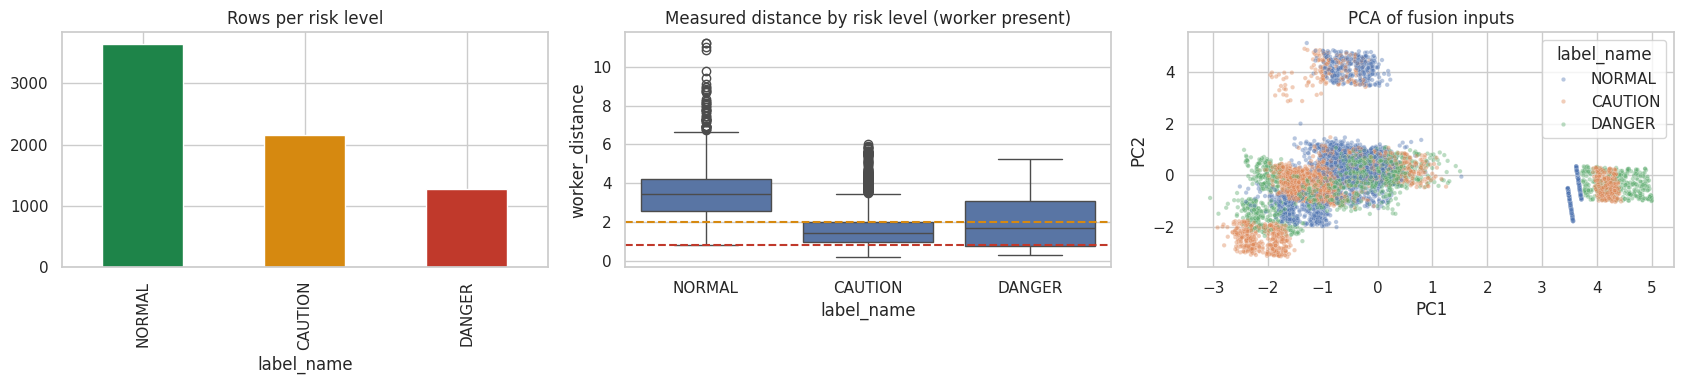

In [9]:
save_table(fusion_df["label_name"].value_counts().reindex(CLASS_NAMES).to_frame("rows"), "eda_class_counts")
save_table(fusion_df[FEATURE_COLS].describe().T.round(3), "eda_feature_summary")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
fusion_df["label_name"].value_counts().reindex(CLASS_NAMES).plot(kind="bar", ax=axes[0], color=["#1e8449", "#d68910", "#c0392b"])
axes[0].set_title("Rows per risk level")
present = fusion_df[fusion_df["worker_detected"] >= 0.5]
sns.boxplot(data=present, x="label_name", y="worker_distance", order=CLASS_NAMES, ax=axes[1])
axes[1].axhline(DANGER_ZONE_M, ls="--", c="#c0392b")
axes[1].axhline(CAUTION_ZONE_M, ls="--", c="#d68910")
axes[1].set_title("Measured distance by risk level (worker present)")
coords = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(fusion_df[FEATURE_COLS]))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=fusion_df["label_name"], hue_order=CLASS_NAMES, s=10, alpha=0.4, ax=axes[2])
axes[2].set(title="PCA of fusion inputs", xlabel="PC1", ylabel="PC2")
save_figure("eda_fusion")

## 3. Trial holdout split

Frames of one trial are near-identical in time, so whole trials are held out: about 15 % for validation and 15 % for test, within each scenario (synthetic) or each majority label (real logs). With real logs, every risk level needs at least three trials or recordings.

In [10]:
trial_meta = fusion_df.groupby("trial_id").agg(scenario=("scenario", "first"), majority=("label_name", lambda s: s.mode().iloc[0]))
strata = "majority" if DATA_SOURCE == "real_logs" else "scenario"
if DATA_SOURCE == "real_logs":
    per_label = trial_meta["majority"].value_counts().reindex(CLASS_NAMES, fill_value=0)
    if (per_label < 3).any():
        raise ValueError(f"Each risk level needs at least 3 trials or recordings; have {per_label.to_dict()}")

split_rng = np.random.default_rng(SEED)
trial_split: Dict[Any, str] = {}
for _stratum, group in trial_meta.groupby(strata):
    ids = split_rng.permutation(group.index.to_numpy())
    n_hold = max(1, int(round(0.15 * len(ids))))
    for i, trial in enumerate(ids):
        trial_split[trial] = "test" if i < n_hold else ("val" if i < 2 * n_hold else "train")
fusion_df["split"] = fusion_df["trial_id"].map(trial_split)

SPLITS = {name: fusion_df[fusion_df["split"] == name] for name in ("train", "val", "test")}
X = {name: frame[FEATURE_COLS].to_numpy(dtype=np.float32) for name, frame in SPLITS.items()}
y = {name: frame["label"].to_numpy(dtype=np.int64) for name, frame in SPLITS.items()}
save_table(pd.DataFrame({
    "trials": fusion_df.groupby("split")["trial_id"].nunique(),
    **{f"{c} rows": fusion_df[fusion_df["label_name"] == c].groupby("split").size() for c in CLASS_NAMES},
}).reindex(["train", "val", "test"]).fillna(0).astype(int), "split_summary")

,trials,NORMAL rows,CAUTION rows,DANGER rows
split,,,,
train,96,2382,1499,838
val,24,583,377,222
test,24,684,279,216


PosixPath('/content/drive/MyDrive/SAMS/results/fusion/split_summary.csv')

## 4. Experiment utilities

Each experiment is trained on the training trials, scored on validation (used for selection) and on test (reported only), and saved with its metadata. The metadata carries the whole live contract: input order, zones, absent-worker values, the motion window and the rules.

In [11]:
LEDGER_PATH = RESULTS_DIR / "fusion_experiment_ledger.csv"
EXPERIMENTS: Dict[str, Any] = {}


def live_contract() -> Dict[str, Any]:
    return {
        "contract_version": 2,
        "class_names": CLASS_NAMES,
        "label_to_idx": LABEL_TO_IDX,
        "feature_cols": FEATURE_COLS,
        "zones_m": {"caution": CAUTION_ZONE_M, "danger": DANGER_ZONE_M},
        "absent_worker": ABSENT_WORKER,
        "motion_window_s": MOTION_WINDOW_S,
        "label_rules": {
            "nearby_m": NEARBY_M,
            "fast_approach_mps": FAST_APPROACH_MPS,
            "fire_alarm_score": FIRE_ALARM_SCORE,
            "smoke_alarm_score": SMOKE_ALARM_SCORE,
            "vibration_abnormal_score": VIBRATION_ABNORMAL_SCORE,
        },
    }


def run_experiment(exp_id: str, approach: str, model, hyperparams: List[Dict[str, Any]]) -> None:
    register_hyperparams(exp_id, hyperparams)
    model.fit(X["train"], y["train"])
    val = compute_metrics(y["val"], model.predict(X["val"]))
    test_pred = model.predict(X["test"])
    test = compute_metrics(y["test"], test_pred)
    EXPERIMENTS[exp_id] = {"model": model, "val": val, "test": test}

    out_dir = MODELS_DIR / exp_id
    out_dir.mkdir(parents=True, exist_ok=True)
    joblib.dump(model, out_dir / "model.joblib")
    meta = {
        "experiment_id": exp_id,
        "approach": approach,
        "task": "fusion_risk_classification",
        "dataset": DATA_SOURCE,
        **live_contract(),
        "split": {"strategy": "trial_holdout", **{f"{s}_trials": sorted(SPLITS[s]["trial_id"].unique().tolist()) for s in SPLITS}},
        "val_metrics": {k: v for k, v in val.items() if k != "classification_report"},
        "test_metrics": {k: v for k, v in test.items() if k != "classification_report"},
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    }
    (out_dir / "metadata.json").write_text(json.dumps(meta, indent=2, default=to_json_safe))

    print(f"{exp_id}: val DANGER recall {val['danger_recall']:.4f} | val macro-F1 {val['f1_macro']:.4f} | test DANGER recall {test['danger_recall']:.4f}")
    print(test["classification_report"])
    by_rule = SPLITS["test"].assign(pred=[CLASS_NAMES[i] for i in test_pred])
    by_rule["correct"] = by_rule["pred"] == by_rule["label_name"]
    save_table(by_rule.groupby(["label_name", "rule"])["correct"].agg(["size", "mean"]).rename(columns={"size": "test rows", "mean": "share correct"}).round(3), f"test_by_rule_{exp_id}")

    row = {
        "experiment_id": exp_id,
        "approach": approach,
        **{f"val_{k}": val[k] for k in ("danger_recall", "f1_macro", "false_alarm_rate")},
        **{f"test_{k}": test[k] for k in ("danger_recall", "f1_macro", "missed_dangers", "dangers_called_normal", "false_alarm_rate")},
        "timestamp_utc": meta["timestamp_utc"],
    }
    ledger = pd.DataFrame([row])
    if LEDGER_PATH.exists():
        previous = pd.read_csv(LEDGER_PATH)
        if "val_f1_macro" in previous.columns:
            ledger = pd.concat([previous[previous["experiment_id"] != exp_id], ledger], ignore_index=True)
    ledger.to_csv(LEDGER_PATH, index=False)

## 5. Experiments

| Id | Model | Why |
|---|---|---|
| `fusion_exp01_random_forest` | Random Forest | Robust baseline for threshold-like rules on mixed binary and continuous inputs |
| `fusion_exp02_xgboost` | XGBoost | Boosted trees, usually the strongest on tabular data |
| `fusion_exp03_svm_rbf` | RBF SVM on scaled inputs | Smooth boundaries; a contrast to axis-aligned trees |
| `fusion_exp04_mlp` | Two-layer MLP with early stopping | A neural baseline |

Every model must expose `predict_proba`, because the live service reports the probability of each level.

In [12]:
run_experiment(
    "fusion_exp01_random_forest", "Random Forest on fusion inputs",
    RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=SEED, n_jobs=-1),
    [{"parameter": "n_estimators", "value": 400, "meaning": "Trees"},
     {"parameter": "class_weight", "value": "balanced", "meaning": "Weight levels by inverse frequency"}],
)

,value,meaning
parameter,,
n_estimators,400,Trees
class_weight,balanced,Weight levels by inverse frequency


fusion_exp01_random_forest: val DANGER recall 1.0000 | val macro-F1 0.9988 | test DANGER recall 1.0000
              precision    recall  f1-score   support

      NORMAL     0.9971    1.0000    0.9985       684
     CAUTION     1.0000    0.9892    0.9946       279
      DANGER     0.9954    1.0000    0.9977       216

    accuracy                         0.9975      1179
   macro avg     0.9975    0.9964    0.9969      1179
weighted avg     0.9975    0.9975    0.9975      1179



test rows  share correct
label_name rule                                                                    
CAUTION    PPE missing near running machine                       37          0.946
           running machine, worker in caution zone               164          0.994
           smoke                                                  78          1.000
DANGER     fallen worker                                          57          1.000
           fire                                                   89          1.000
           running machine, fast approach in caution zone         25          1.000
           running machine, worker in danger zone                 45          1.000
NORMAL     no hazard near a worker                               684          1.000

In [13]:
run_experiment(
    "fusion_exp02_xgboost", "XGBoost on fusion inputs",
    XGBClassifier(objective="multi:softprob", n_estimators=250, max_depth=5, learning_rate=0.1, random_state=SEED, n_jobs=-1),
    [{"parameter": "objective", "value": "multi:softprob", "meaning": "Outputs a probability per level"},
     {"parameter": "n_estimators", "value": 250, "meaning": "Boosting rounds"},
     {"parameter": "max_depth", "value": 5, "meaning": "Tree depth"},
     {"parameter": "learning_rate", "value": 0.1, "meaning": "Shrinkage"}],
)

,value,meaning
parameter,,
objective,multi:softprob,Outputs a probability per level
n_estimators,250,Boosting rounds
max_depth,5,Tree depth
learning_rate,0.1,Shrinkage


fusion_exp02_xgboost: val DANGER recall 1.0000 | val macro-F1 0.9981 | test DANGER recall 1.0000
              precision    recall  f1-score   support

      NORMAL     1.0000    1.0000    1.0000       684
     CAUTION     1.0000    0.9964    0.9982       279
      DANGER     0.9954    1.0000    0.9977       216

    accuracy                         0.9992      1179
   macro avg     0.9985    0.9988    0.9986      1179
weighted avg     0.9992    0.9992    0.9992      1179



test rows  share correct
label_name rule                                                                    
CAUTION    PPE missing near running machine                       37          1.000
           running machine, worker in caution zone               164          0.994
           smoke                                                  78          1.000
DANGER     fallen worker                                          57          1.000
           fire                                                   89          1.000
           running machine, fast approach in caution zone         25          1.000
           running machine, worker in danger zone                 45          1.000
NORMAL     no hazard near a worker                               684          1.000

In [14]:
run_experiment(
    "fusion_exp03_svm_rbf", "RBF SVM on scaled fusion inputs",
    Pipeline([("scaler", StandardScaler()), ("clf", SVC(C=5.0, kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))]),
    [{"parameter": "C", "value": 5.0, "meaning": "Regularisation"},
     {"parameter": "class_weight", "value": "balanced", "meaning": "Weight levels by inverse frequency"}],
)

,value,meaning
parameter,,
C,5.0,Regularisation
class_weight,balanced,Weight levels by inverse frequency


fusion_exp03_svm_rbf: val DANGER recall 1.0000 | val macro-F1 0.9952 | test DANGER recall 0.9954
              precision    recall  f1-score   support

      NORMAL     0.9841    0.9985    0.9913       684
     CAUTION     0.9925    0.9534    0.9726       279
      DANGER     0.9908    0.9954    0.9931       216

    accuracy                         0.9873      1179
   macro avg     0.9892    0.9824    0.9856      1179
weighted avg     0.9873    0.9873    0.9872      1179



test rows  share correct
label_name rule                                                                    
CAUTION    PPE missing near running machine                       37          0.703
           running machine, worker in caution zone               164          0.988
           smoke                                                  78          1.000
DANGER     fallen worker                                          57          1.000
           fire                                                   89          1.000
           running machine, fast approach in caution zone         25          0.960
           running machine, worker in danger zone                 45          1.000
NORMAL     no hazard near a worker                               684          0.999

In [15]:
run_experiment(
    "fusion_exp04_mlp", "MLP on scaled fusion inputs",
    Pipeline([("scaler", StandardScaler()), ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=MLP_MAX_ITER, early_stopping=True,
                                                                   validation_fraction=0.15, n_iter_no_change=MLP_PATIENCE, random_state=SEED))]),
    [{"parameter": "hidden_layer_sizes", "value": "(64, 32)", "meaning": "Layer widths"},
     {"parameter": "early_stopping", "value": True, "meaning": "Stop when the internal validation score plateaus"},
     {"parameter": "n_iter_no_change", "value": MLP_PATIENCE, "meaning": "Patience"}],
)

,value,meaning
parameter,,
hidden_layer_sizes,"(64, 32)",Layer widths
early_stopping,True,Stop when the internal validation score plateaus
n_iter_no_change,15,Patience


fusion_exp04_mlp: val DANGER recall 1.0000 | val macro-F1 0.9959 | test DANGER recall 0.9954
              precision    recall  f1-score   support

      NORMAL     0.9884    0.9971    0.9927       684
     CAUTION     0.9890    0.9677    0.9783       279
      DANGER     0.9954    0.9954    0.9954       216

    accuracy                         0.9898      1179
   macro avg     0.9909    0.9867    0.9888      1179
weighted avg     0.9898    0.9898    0.9898      1179



test rows  share correct
label_name rule                                                                    
CAUTION    PPE missing near running machine                       37          0.784
           running machine, worker in caution zone               164          0.994
           smoke                                                  78          1.000
DANGER     fallen worker                                          57          1.000
           fire                                                   89          1.000
           running machine, fast approach in caution zone         25          0.960
           running machine, worker in danger zone                 45          1.000
NORMAL     no hazard near a worker                               684          0.997

## 6. Compare, check and promote

### 6.1 Comparison

Ranked by validation DANGER recall, then validation macro-F1. The test columns show missed dangers, and the dangers called NORMAL (the worst error) for each model.

In [16]:
EXPERIMENT_IDS = ["fusion_exp01_random_forest", "fusion_exp02_xgboost", "fusion_exp03_svm_rbf", "fusion_exp04_mlp"]
ledger = pd.read_csv(LEDGER_PATH)
comparison = (ledger[ledger["experiment_id"].isin(EXPERIMENT_IDS)]
              .sort_values(["val_danger_recall", "val_f1_macro"], ascending=False).set_index("experiment_id"))
save_table(comparison.drop(columns=["timestamp_utc"]).round(4), "experiment_comparison")
winner_id = comparison.index[0]
print("Winner on validation:", winner_id)

,approach,val_danger_recall,val_f1_macro,val_false_alarm_rate,test_danger_recall,test_f1_macro,test_missed_dangers,test_dangers_called_normal,test_false_alarm_rate
experiment_id,,,,,,,,,
fusion_exp01_random_forest,Random Forest on fusion inputs,1.0,0.9988,0.0000,1.0000,0.9969,0,0,0.0000
fusion_exp02_xgboost,XGBoost on fusion inputs,1.0,0.9981,0.0000,1.0000,0.9986,0,0,0.0000
fusion_exp04_mlp,MLP on scaled fusion inputs,1.0,0.9959,0.0069,0.9954,0.9888,1,0,0.0029
fusion_exp03_svm_rbf,RBF SVM on scaled fusion inputs,1.0,0.9952,0.0069,0.9954,0.9856,1,0,0.0015


Winner on validation: fusion_exp01_random_forest


### 6.2 Winner's test confusion matrix

,pred NORMAL,pred CAUTION,pred DANGER
true NORMAL,684,0,0
true CAUTION,2,276,1
true DANGER,0,0,216


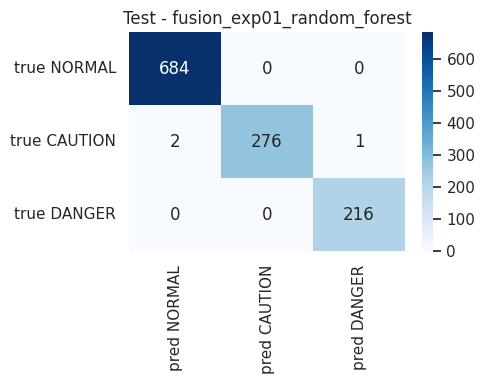

In [17]:
cm = pd.DataFrame(EXPERIMENTS[winner_id]["test"]["confusion_matrix"], index=[f"true {c}" for c in CLASS_NAMES], columns=[f"pred {c}" for c in CLASS_NAMES])
save_table(cm, "winner_confusion_test")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title(f"Test - {winner_id}")
save_figure("winner_confusion_test")

### 6.3 Check scenarios

Hand-written situations with the label the policy requires, including the cases version 1 got wrong (a worker close to a stopped machine, an empty frame, fire far from the worker). The promoted model is the best-ranked experiment that gives the expected label in every one. If none does, the notebook stops: the training data does not cover that situation well enough.

In [18]:
def scene(**changes) -> Dict[str, float]:
    base = {"worker_detected": 1.0, "worker_distance": 3.5, "inside_caution_zone": 0.0, "inside_danger_zone": 0.0,
            "worker_speed": 0.1, "approaching_machine": 0.0, "vision_confidence": 0.85, "ppe_missing": 0.0,
            "machine_active": 1.0, "vibration_state": 0.0, "vibration_anomaly_score": 0.2,
            "fire_score": 0.0, "smoke_score": 0.0, "fall_detected": 0.0}
    base.update(changes)
    base["inside_caution_zone"] = float(base["worker_detected"] >= 0.5 and base["worker_distance"] <= CAUTION_ZONE_M)
    base["inside_danger_zone"] = float(base["worker_detected"] >= 0.5 and base["worker_distance"] <= DANGER_ZONE_M)
    return base


CHECKS = {
    "empty frame, machine running": scene(worker_detected=0.0, **ABSENT_WORKER),
    "empty frame, machine stopped": scene(worker_detected=0.0, machine_active=0.0, **ABSENT_WORKER),
    "worker far, machine running": scene(),
    "worker at 1.5 m, machine running": scene(worker_distance=1.5),
    "worker at 0.5 m, machine running": scene(worker_distance=0.5),
    "worker at 0.5 m, machine stopped": scene(worker_distance=0.5, machine_active=0.0, vibration_anomaly_score=0.1),
    "worker rushing in at 1.6 m": scene(worker_distance=1.6, worker_speed=1.2, approaching_machine=1.0),
    "fire, worker far": scene(fire_score=0.6),
    "fire, nobody in view": scene(worker_detected=0.0, fire_score=0.6, **ABSENT_WORKER),
    "smoke, worker far": scene(smoke_score=0.7),
    "fallen worker far from machine": scene(fall_detected=1.0, worker_speed=0.0, vision_confidence=0.6),
    "abnormal vibration, worker at 2.5 m": scene(worker_distance=2.5, vibration_state=1.0, vibration_anomaly_score=0.8),
    "abnormal vibration, worker far": scene(worker_distance=5.0, vibration_state=1.0, vibration_anomaly_score=0.8),
    "PPE missing at 2.5 m": scene(worker_distance=2.5, ppe_missing=1.0),
    "PPE missing far away": scene(worker_distance=5.0, ppe_missing=1.0),
}
check_rows = np.array([[row[c] for c in FEATURE_COLS] for row in CHECKS.values()], dtype=np.float32)
check_table = pd.DataFrame({"expected": [assign_risk(row)[0] for row in CHECKS.values()], "rule": [assign_risk(row)[1] for row in CHECKS.values()]}, index=list(CHECKS))
for exp_id in comparison.index:
    check_table[exp_id] = [CLASS_NAMES[i] for i in EXPERIMENTS[exp_id]["model"].predict(check_rows)]
save_table(check_table, "check_scenarios")
passing = [exp_id for exp_id in comparison.index if (check_table[exp_id] == check_table["expected"]).all()]
assert passing, "No experiment gives the expected label in every check scenario; see the table above."
if passing[0] != winner_id:
    print(f"{winner_id} fails a check scenario; promoting the best-ranked experiment that passes them all instead.")
winner_id = passing[0]
print(f"{winner_id} passes all {len(CHECKS)} check scenarios.")

,expected,rule,fusion_exp01_random_forest,fusion_exp02_xgboost,fusion_exp04_mlp,fusion_exp03_svm_rbf
"empty frame, machine running",NORMAL,no hazard near a worker,NORMAL,NORMAL,NORMAL,NORMAL
"empty frame, machine stopped",NORMAL,no hazard near a worker,NORMAL,NORMAL,NORMAL,NORMAL
"worker far, machine running",NORMAL,no hazard near a worker,NORMAL,NORMAL,NORMAL,NORMAL
"worker at 1.5 m, machine running",CAUTION,"running machine, worker in caution zone",CAUTION,CAUTION,CAUTION,CAUTION
"worker at 0.5 m, machine running",DANGER,"running machine, worker in danger zone",DANGER,DANGER,DANGER,DANGER
"worker at 0.5 m, machine stopped",CAUTION,"stopped machine, worker in danger zone",CAUTION,CAUTION,CAUTION,CAUTION
worker rushing in at 1.6 m,DANGER,"running machine, fast approach in caution zone",DANGER,DANGER,DANGER,DANGER
"fire, worker far",DANGER,fire,DANGER,DANGER,DANGER,DANGER
"fire, nobody in view",DANGER,fire,DANGER,DANGER,DANGER,DANGER
"smoke, worker far",CAUTION,smoke,CAUTION,CAUTION,CAUTION,CAUTION


fusion_exp01_random_forest passes all 15 check scenarios.


### 6.4 Promote

The winner is copied to `best_fusion_model/` with its metadata. The live service reads `feature_cols`, `zones_m` and `absent_worker` from there. While this model is live, labelled trials record all of its inputs, so the next retrain can use real rows.

In [19]:
best_dir = MODELS_DIR / "best_fusion_model"
best_dir.mkdir(parents=True, exist_ok=True)
shutil.copy2(MODELS_DIR / winner_id / "model.joblib", best_dir / "model.joblib")
winner_meta = json.loads((MODELS_DIR / winner_id / "metadata.json").read_text())
winner_meta.update({"promoted_from": winner_id, "selection_metric": "val_danger_recall, then val_f1_macro", "check_scenarios_passed": len(CHECKS)})
(best_dir / "metadata.json").write_text(json.dumps(winner_meta, indent=2, default=to_json_safe))

reloaded = joblib.load(best_dir / "model.joblib")
assert hasattr(reloaded, "predict_proba") and reloaded.predict_proba(check_rows).shape == (len(CHECKS), 3)
print("Promoted", winner_id, "to", best_dir)
print("Copy models/fusion/best_fusion_model/ into the repository to deploy it.")

Promoted fusion_exp01_random_forest to /content/drive/MyDrive/SAMS/models/fusion/best_fusion_model
Copy models/fusion/best_fusion_model/ into the repository to deploy it.
